# Benchmark: a beta mean and a beta precision

A beta response takes values strictly between 0 and 1. A beta regression gives it a mean and a precision, with variance `mu (1 - mu) / (1 + phi)`. When the precision also depends on a covariate, a constant-precision model estimates the mean while using the same precision for every row. This study asks whether `BetaLSS` recovers both, against statsmodels `BetaModel`, which uses the same logit link for the mean and the same log link for the precision.

Two tasks, four standard normal predictors. `noise` is unused.

* **linear**: `logit mu = 0.15 + 0.50 x1 - 0.35 x2` and `log phi = 1.80 + 0.65 x3`.
* **smooth**: `logit mu = 0.10 + sin(1.4 x1) + 0.25 x2` and `log phi = 1.60 + 0.55 sin(2 x3)`.

Each fit sees 1,500 training rows and is scored on the same 4,000 test rows (one test sample per task, four training seeds). mboostrs chooses `mstop` by 5-fold cross-validation over every step, `nu=0.1`. The fits are non-cyclic (each step updates only the parameter whose update most lowers the risk), so the budget is one total step count: 600 for a linear model and 1,200 for an additive model.

scikit-learn has no beta regression. R is not installed. A `BetaModel` fit that does not converge is left out of the means below; the count of those fits is reported separately.

**Own score** is the test mean negative log density, in nats per row. **At the true precision** plugs the generating precision into every fit's predicted mean.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional distribution of a proportion whose precision depends on a covariate |
| **Observed response** | a simulated beta draw in (0, 1) |
| **Estimand** | test mean negative log density; absolute error of the mean and of log precision |
| **Units** | nats per row; the response is a proportion |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | one shared test sample per task; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | `nu=0.1`; 600 steps for a linear model and 1,200 for an additive model; cross-validation evaluates every step |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Not claimed** | that every proportion is beta, or that these step counts are optimal on other designs |

:::


## Reproduction

From the repository root, with `statsmodels` and `patsy` installed:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
    python benches/bench_beta.py --out docs/book/cases/bench_beta.json
```

The tables below read that file.

The output file records the library versions and the protocol in `provenance`. Timing standard
deviations and standard errors describe variation across the training
seeds. Each method has its own fit, tuning and prediction workload, as
defined by the runner; these elapsed times describe those workflows.


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_beta.json").read_text())


def finite(value):
    if value is None or value != value or value in (float("inf"), float("-inf")):
        return None
    return value


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    if record.get("converged") is False:
        continue
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "own_nll": finite(record["own_nll"]),
        "nll_true": finite(record["nll_at_true_phi"]),
        "mae": finite(record["mae"]),
        "mae_log_phi": finite(record["mae_log_phi"]),
        "phi": finite(record["phi_mean"]),
        "seconds": record["seconds"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("own_nll").mean(),
        pl.col("nll_true").mean(),
        pl.col("mae").mean(),
        pl.col("mae_log_phi").mean(),
        pl.col("phi").mean(),
        pl.col("seconds").mean(),
        pl.col("mstop").mean(),
        pl.col("own_nll").count().alias("n_finite"),
    )
    .sort("task", "own_nll")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


def n_failed(task, method):
    return sum(
        1
        for record in bench["results"]
        if record["task"] == task
        and record["method"] == method
        and record.get("converged") is False
    )


In [5]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def n_at_cap(task, method):
    return sum(
        1
        for record in bench["results"]
        if record["task"] == task and record["method"] == method and record.get("at_boundary")
    )


In [6]:
scored = summary.filter(pl.col("method") != "generating Beta")
table(
    scored.select("task", "method", "own_nll", "nll_true", "mae", "mae_log_phi", "phi", "seconds"),
    title="Beta mean and precision",
    subtitle="Mean over seeds whose score is finite; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "own_nll": "own log score",
        "nll_true": "at true precision",
        "mae": "MAE",
        "mae_log_phi": "log-precision MAE",
        "phi": "mean precision",
        "seconds": "seconds",
    },
    better={"own_nll": "min", "mae": "min", "mae_log_phi": "min"},
    formats={"nll_true": 4, "phi": 2, "seconds": 3},
    notes=(
        "Own log score is the test negative log density, in nats per row. "
        "At true precision scores every predicted mean with the generating precision. "
        "phi is the precision in Var = mu (1 - mu) / (1 + phi). "
        "A BetaModel fit that did not converge is omitted from its mean. "
        "Lower is better. Bold marks the best scored value in each task.",
    ),
)


GT(_tbl_data=shape: (10, 8)
┌────────┬─────────────┬───────────┬───────────┬──────────┬─────────────┬──────────┬───────────┐
│ task   ┆ method      ┆ own_nll   ┆ nll_true  ┆ mae      ┆ mae_log_phi ┆ phi      ┆ seconds   │
│ ---    ┆ ---         ┆ ---       ┆ ---       ┆ ---      ┆ ---         ┆ ---      ┆ ---       │
│ str    ┆ str         ┆ f64       ┆ f64       ┆ f64      ┆ f64         ┆ f64      ┆ f64       │
╞════════╪═════════════╪═══════════╪═══════════╪══════════╪═════════════╪══════════╪═══════════╡
│ linear ┆ mboostrs    ┆ -0.399816 ┆ -0.400819 ┆ 0.005167 ┆ 0.056681    ┆ 7.218556 ┆ 2.732483  │
│        ┆ glmboostLSS ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ BetaLSS     ┆           ┆           ┆          ┆             ┆          ┆           │
│ linear ┆ statsmodels ┆ -0.399117 ┆ -0.400806 ┆ 0.005215 ┆ 0.063769    ┆ 7.573895 ┆ 0.006233  │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│ linear ┆ mboostrs    ┆ -0.397928 ┆ -0.399427 ┆ 0.007733 ┆ 0.068356    ┆ 7.19149  ┆ 13.390042 │
│        ┆ gamboostLSS ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ BetaLSS     ┆           ┆           ┆          ┆             ┆          ┆           │
│ linear ┆ statsmodels ┆ -0.389889 ┆ -0.399101 ┆ 0.0126   ┆ 0.108812    ┆ 8.569606 ┆ 0.066507  │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ spline      ┆           ┆           ┆          ┆             ┆          ┆           │
│ linear ┆ statsmodels ┆ -0.264803 ┆ -0.399063 ┆ 0.008107 ┆ 0.569796    ┆ 4.538978 ┆ 0.00431   │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ constant…   ┆           ┆           ┆          ┆             ┆          ┆           │
│ smooth ┆ mboostrs    ┆ -0.338773 ┆ -0.339878 ┆ 0.011448 ┆ 0.077486    ┆ 5.324233 ┆ 15.128704 │
│        ┆ gamboostLSS ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ BetaLSS     ┆           ┆           ┆          ┆             ┆          ┆           │
│ smooth ┆ statsmodels ┆ -0.330604 ┆ -0.337198 ┆ 0.014138 ┆ 0.072161    ┆ 5.507122 ┆ 0.080483  │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ spline      ┆           ┆           ┆          ┆             ┆          ┆           │
│ smooth ┆ mboostrs    ┆ -0.182967 ┆ -0.195037 ┆ 0.078352 ┆ 0.408116    ┆ 3.522377 ┆ 4.030501  │
│        ┆ glmboostLSS ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ BetaLSS     ┆           ┆           ┆          ┆             ┆          ┆           │
│ smooth ┆ statsmodels ┆ -0.181593 ┆ -0.197602 ┆ 0.074573 ┆ 0.394577    ┆ 3.644805 ┆ 0.01654   │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│ smooth ┆ statsmodels ┆ -0.180772 ┆ -0.196341 ┆ 0.077009 ┆ 0.414405    ┆ 3.560112 ┆ 0.005015  │
│        ┆ BetaModel   ┆           ┆           ┆          ┆             ┆          ┆           │
│        ┆ constant…   ┆           ┆           ┆          ┆             ┆          ┆           │
└────────┴─────────────┴───────────┴───────────┴──────────┴─────────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10c469cd0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='own_nll', type=<ColInfoTypeEnum.default: 1>, column_label='own log score', column_align='right', column_width=None), ColInfo(var='nll_true', type=<ColInfoTypeEnum.default: 1>, column_label='at true precision', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE', column_align='right',

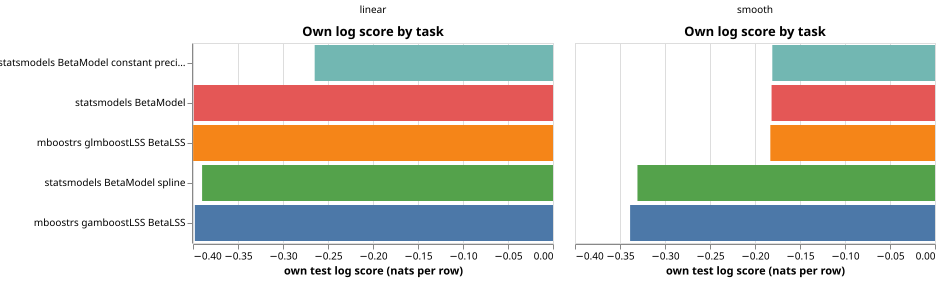

In [7]:
chart_rows = summary.filter(
    (pl.col("method") != "generating Beta") & pl.col("own_nll").is_not_null()
)
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("own_nll:Q", title="own test log score (nats per row)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=360,
    height=200,
    title="Own log score by task",
).facet(column=alt.Column("task:N", title=None))


(the-linear-mean-with-a-precision-that-moves)=
## Linear mean and varying precision

`glmboostLSS` with `BetaLSS` matches `BetaModel` with a precision equation. Mean own log score is {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'own_nll'):.4f}"` against {eval}`f"{value('linear', 'statsmodels BetaModel', 'own_nll'):.4f}"` for statsmodels and {eval}`f"{value('linear', 'generating Beta', 'own_nll'):.4f}"` for the generating density. Absolute error of the mean is {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'mae'):.3f}"` and {eval}`f"{value('linear', 'statsmodels BetaModel', 'mae'):.3f}"`. Log-precision error is {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'mae_log_phi'):.3f}"` and {eval}`f"{value('linear', 'statsmodels BetaModel', 'mae_log_phi'):.3f}"`. The mean precision is {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'phi'):.2f}"` against the generating {eval}`f"{value('linear', 'generating Beta', 'phi'):.2f}"`. Cross-validation stopped inside the 600-step path on every seed (mean chosen step {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'mstop'):.0f}"`, {eval}`f"{n_at_cap('linear', 'mboostrs glmboostLSS BetaLSS')}"` at the cap). The MLE takes about {eval}`f"{value('linear', 'statsmodels BetaModel', 'seconds'):.3f}"` seconds; the cross-validated boost takes about {eval}`f"{value('linear', 'mboostrs glmboostLSS BetaLSS', 'seconds'):.1f}"`.

The constant-precision model uses one fitted precision for all test rows. Its own score is {eval}`f"{value('linear', 'statsmodels BetaModel constant precision', 'own_nll'):.3f}"`, about {eval}`f"{value('linear', 'statsmodels BetaModel constant precision', 'own_nll') - value('linear', 'statsmodels BetaModel', 'own_nll'):.2f}"` nats per row worse. Scored at the generating precision, that same mean is {eval}`f"{value('linear', 'statsmodels BetaModel constant precision', 'nll_true'):.4f}"`, next to the full model's {eval}`f"{value('linear', 'statsmodels BetaModel', 'nll_true'):.4f}"`. The similar scores at the generating precision indicate that the own-score gap mainly reflects the precision model. On seed 0 the constant fit's log precision is {eval}`f"{bench['recovery']['constant_precision']['precision']:.3f}"` against the full model's intercept {eval}`f"{bench['recovery']['statsmodels_precision_params']['Intercept']:.3f}"` and slope on `x3` of {eval}`f"{bench['recovery']['statsmodels_precision_params']['x3']:.3f}"` (generating slope 0.65).

A B-spline `BetaModel` on this linear truth did not converge on {eval}`f"{n_failed('linear', 'statsmodels BetaModel spline')}"` of four seeds. The mean in the table keeps the seed that stayed finite. The richer spline specification has convergence failures on this linear task, including infinite fitted precision.


(the-smooth-mean-and-the-smooth-precision)=
## Smooth mean and precision

A linear beta misses the sine. `glmboostLSS` scores {eval}`f"{value('smooth', 'mboostrs glmboostLSS BetaLSS', 'own_nll'):.3f}"` and the constant-precision `BetaModel` scores {eval}`f"{value('smooth', 'statsmodels BetaModel constant precision', 'own_nll'):.3f}"`. Absolute error of the mean is about {eval}`f"{value('smooth', 'mboostrs glmboostLSS BetaLSS', 'mae'):.3f}"`. The linear `BetaModel` with a precision equation did not converge on {eval}`f"{n_failed('smooth', 'statsmodels BetaModel')}"` of four seeds; the mean above uses the seeds that converged and is still the linear score, about {eval}`f"{value('smooth', 'statsmodels BetaModel', 'own_nll'):.3f}"`. The missed curve is not repaired by letting the precision be linear.

`gamboostLSS` with `bbs(x1)` and `bbs(x3)` scores {eval}`f"{value('smooth', 'mboostrs gamboostLSS BetaLSS', 'own_nll'):.4f}"`. The B-spline `BetaModel` scores {eval}`f"{value('smooth', 'statsmodels BetaModel spline', 'own_nll'):.4f}"`. The generating density scores {eval}`f"{value('smooth', 'generating Beta', 'own_nll'):.4f}"`. Absolute error of the mean is {eval}`f"{value('smooth', 'mboostrs gamboostLSS BetaLSS', 'mae'):.3f}"` against {eval}`f"{value('smooth', 'statsmodels BetaModel spline', 'mae'):.3f}"`, and log-precision error is {eval}`f"{value('smooth', 'mboostrs gamboostLSS BetaLSS', 'mae_log_phi'):.3f}"` against {eval}`f"{value('smooth', 'statsmodels BetaModel spline', 'mae_log_phi'):.3f}"`. At the true precision the smooth boost is {eval}`f"{value('smooth', 'mboostrs gamboostLSS BetaLSS', 'nll_true'):.4f}"`, so most of what it gains on the linear model is the mean, and the rest is the precision. The boost takes about {eval}`f"{value('smooth', 'mboostrs gamboostLSS BetaLSS', 'seconds'):.0f}"` seconds. No additive path stopped at the 1,200-step cap ({eval}`f"{n_at_cap('smooth', 'mboostrs gamboostLSS BetaLSS')}"`).


## Prediction and parameter accessors

The calls below were made on the first linear training sample.

`predict` defaults to `type="link"`. For `BetaLSS` that is the logit of the mean and the log precision, not the mean and the precision. {eval}`probe("predict default is logit mu and log phi")["detail"]` The benchmark uses `type="response"`. `phi` is the precision in `Var = mu (1 - mu) / (1 + phi)`, not a variance and not a coefficient of variation.

`logLik()` is the beta density. On an 80-step path this sample reports:

> {eval}`probe("BetaLSS logLik is the beta density")["detail"]`

The cross-validated fit agrees. Seed 0 reports `logLik()` {eval}`f"{bench['recovery']['lss_loglik']:.6f}"` against the beta density {eval}`f"{bench['recovery']['lss_scipy_loglik']:.6f}"`. The statsmodels `llf` on the same rows is {eval}`f"{bench['recovery']['statsmodels_llf']:.3f}"`.

With no budget, `autospec` considers `GammaReg`, because every value is positive, warns that `GammaReg` has support above 1, and starts from Gaussian. Without a budget that is where it stops, because the distributional check costs one fit per fold:

> {eval}`probe("autospec without a budget")["detail"]`

With a family-probe budget it does not stop there: the probe offers `BetaLSS`, scores it against Gaussian on held-out log score, and adopts it only when it lowers held-out risk by more than the search's margin. The comparison uses the full predictive density, including its precision. The shape, pair, residual-tree and deselection probes (each one held-out comparison that the search runs) are single-predictor machinery, so a search that adopts a distributional family stops at the family and `rec.fit()` builds the distributional model:

> {eval}`probe("autospec with a family-probe budget")["detail"]`

`glmboost(family=BetaLSS())` does not route to `glmboostLSS`. The message says the class is not defined:

> {eval}`probe("glmboost(family=BetaLSS())")["detail"]`

A response of 0 or 1 is refused. {eval}`probe("BetaLSS rejects 0")["error"]`: {eval}`probe("BetaLSS rejects 0")["detail"]` {eval}`probe("BetaLSS rejects 1")["error"]`: {eval}`probe("BetaLSS rejects 1")["detail"]`
